# 05. Model Explainability, SHAP Attributions & Regulatory Adverse Action Notices

## 1. Compliance, Explainability & Governance in Credit Underwriting
Modern consumer credit risk models cannot function as black boxes. Under federal lending regulations—including the **Equal Credit Opportunity Act (ECOA)** and the **Fair Credit Reporting Act (FCRA)**—lending institutions are legally mandated to:

1. **Disclose Principal Adverse Reasons**: If a loan request is denied or granted on less favorable terms, the applicant must receive the top **4 to 5 key factors** that adversely impacted their score.
2. **Audit Global Feature Directionality**: Model risk managers must verify that model behavior aligns with sound economic and financial intuition (e.g. higher leverage or delinquency history must not paradoxically decrease default probability).
3. **Ensure Fairness & Non-Discrimination**: Affirm that protected or proxy attributes are not illicitly driving rejection decisions.

In this notebook, we utilize **SHAP (SHapley Additive exPlanations)** grounded in cooperative game theory to unpack both global portfolio drivers and individual applicant underwriting decisions.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Ensure project root is in sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.predict import (
    load_production_model,
    predict_loan_applicant,
    explain_applicant_shap,
    ADVERSE_ACTION_REASONS
)

# Global visual styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'figure.titlesize': 15,
    'figure.dpi': 120,
})

# Load model bundle and processed dataset
bundle = load_production_model()
pipeline = bundle['pipeline']
feature_names = bundle['feature_names']
optimal_threshold = bundle['optimal_threshold']

data_path = PROJECT_ROOT / 'data' / 'processed' / 'loans_cleaned.parquet'
df = pd.read_parquet(data_path)
X = df.drop(columns=['target'])
y = df['target']

print(f'Champion model loaded: {bundle["model_type"]}')
print(f'Optimal decision threshold: {optimal_threshold}')
print(f'Engineered feature count:   {len(feature_names)}')

C:\Users\dr_ra\Desktop\loan-Prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Champion model loaded: LightGBM Classifier
Optimal decision threshold: 0.37
Engineered feature count:   98


## 2. Global Model Interpretability (SHAP Summary Analysis)

We extract the fitted tree booster and compute SHAP values across an evaluation sample of 500 applicants to observe global risk drivers across the portfolio.

=== TOP 15 GLOBAL RISK DRIVERS (MEAN |SHAP|) ===
               Feature  Mean |SHAP|
              int_rate       0.2851
            annual_inc       0.1948
                  term       0.1920
        inq_last_6mths       0.1163
         sub_grade_ord       0.1098
            revol_util       0.0836
purpose_small_business       0.0598
   purpose_credit_card       0.0455
   revol_bal_to_income       0.0412
         addr_state_CA       0.0395
      emp_length_years       0.0319
        loan_to_income       0.0311
         addr_state_FL       0.0307
  credit_history_years       0.0301
           installment       0.0281


C:\Users\dr_ra\Desktop\loan-Prediction\.venv\Lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


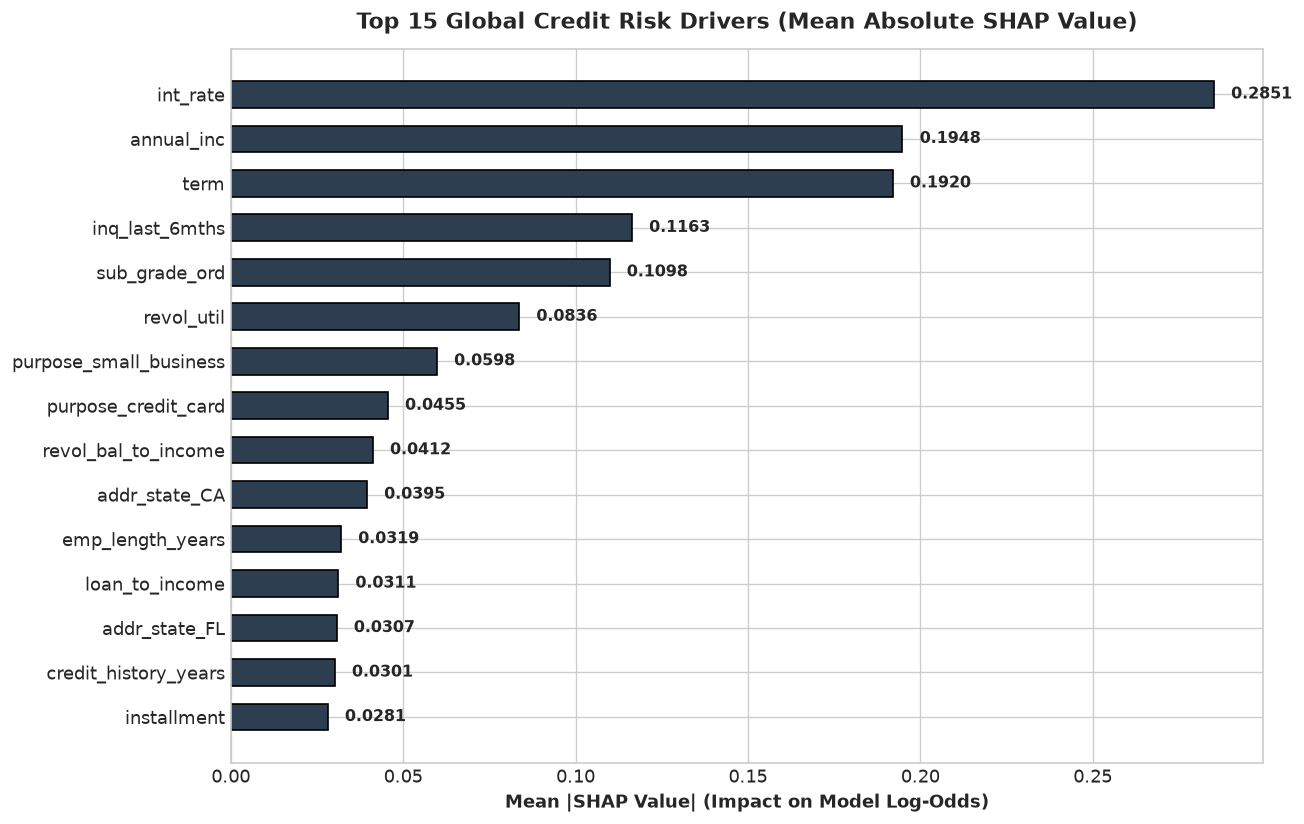

In [2]:
sample_X = X.sample(n=500, random_state=42)
fe_step = pipeline.named_steps['domain_features']
prep_step = pipeline.named_steps['preprocessor']
classifier = pipeline.named_steps['classifier']

sample_fe = fe_step.transform(sample_X)
sample_prep = prep_step.transform(sample_fe)

explainer = shap.TreeExplainer(classifier)
shap_values = explainer.shap_values(sample_prep)

if isinstance(shap_values, list):
    shap_mat = shap_values[1] if len(shap_values) > 1 else shap_values[0]
elif shap_values.ndim == 3:
    shap_mat = shap_values[:, :, 1]
else:
    shap_mat = shap_values

# Mean absolute SHAP values (Global Feature Importance)
mean_abs_shap = np.mean(np.abs(shap_mat), axis=0)
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean |SHAP|': mean_abs_shap
}).sort_values(by='Mean |SHAP|', ascending=False).reset_index(drop=True)

print('=== TOP 15 GLOBAL RISK DRIVERS (MEAN |SHAP|) ===')
print(importance_df.head(15).round(4).to_string(index=False))

# Global Importance Barplot
fig, ax = plt.subplots(figsize=(11, 7))
top_15 = importance_df.head(15).iloc[::-1]
ax.barh(top_15['Feature'], top_15['Mean |SHAP|'], color='#2c3e50', edgecolor='black', height=0.6)
ax.set_title('Top 15 Global Credit Risk Drivers (Mean Absolute SHAP Value)', fontweight='bold', pad=12)
ax.set_xlabel('Mean |SHAP Value| (Impact on Model Log-Odds)', fontweight='bold')
for bar, val in zip(ax.patches, top_15['Mean |SHAP|']):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2, f'{val:.4f}', va='center', fontweight='bold', fontsize=9.5)
plt.tight_layout()
plt.show()

## 3. Local Applicant Scoring & Adverse Action Notice Generation

Under the FCRA, when a credit decision is adverse (REJECT), the applicant must be given specific reasons for denial.
Here we test our automated underwriting engine on two contrasting applicants:
- **Applicant A**: High-risk borrower (elevated debt burden, short credit history, subprime rating).
- **Applicant B**: Prime creditworthy borrower (high income, low utilization, prime rating).

In [3]:
# High-Risk Applicant Simulation
applicant_high_risk = pd.DataFrame([{
    'loan_amnt': 25000.0,
    'term': 60,
    'int_rate': 21.5,
    'installment': 683.0,
    'grade': 'F',
    'sub_grade': 'F2',
    'home_ownership': 'RENT',
    'annual_inc': 35000.0,
    'verification_status': 'Verified',
    'issue_d': 'Dec-11',
    'purpose': 'debt_consolidation',
    'addr_state': 'CA',
    'dti': 28.5,
    'delinq_2yrs': 1,
    'earliest_cr_line': 'Jan-07',
    'inq_last_6mths': 4,
    'open_acc': 12,
    'pub_rec': 1,
    'revol_bal': 19500.0,
    'revol_util': 88.5,
    'total_acc': 18,
    'pub_rec_bankruptcies': 1,
    'emp_length_years': 2.0,
    'emp_length_missing': 0,
}])

# Score applicant
score_a = predict_loan_applicant(applicant_high_risk, model_bundle=bundle)
explain_a = explain_applicant_shap(applicant_high_risk, model_bundle=bundle, top_n=4)

print('======================================================')
print('   CREDIT DECISION REPORT: HIGH-RISK APPLICANT        ')
print('======================================================')
print(f'Requested Loan:        ${score_a["loan_amount"]:,.2f}')
print(f'Default Probability:   {score_a["default_probability_pct"]:.2f}%')
print(f'Optimal Cutoff:        {score_a["decision_threshold"]*100:.1f}%')
print(f'Underwriting Decision: {score_a["decision"]}')
print(f'Assigned Risk Tier:    {score_a["risk_tier"]}')
print(f'Expected Loss:         ${score_a["expected_loss"]:,.2f}')
print('\nREGULATORY ADVERSE ACTION NOTICE REASONS (FCRA COMPLIANT):')
for idx, reason in enumerate(explain_a['adverse_action_reasons'], 1):
    print(f'  {idx}. {reason}')

# Prime Applicant Simulation
applicant_prime = pd.DataFrame([{
    'loan_amnt': 12000.0,
    'term': 36,
    'int_rate': 7.9,
    'installment': 375.0,
    'grade': 'A',
    'sub_grade': 'A3',
    'home_ownership': 'MORTGAGE',
    'annual_inc': 110000.0,
    'verification_status': 'Verified',
    'issue_d': 'Dec-11',
    'purpose': 'home_improvement',
    'addr_state': 'TX',
    'dti': 8.5,
    'delinq_2yrs': 0,
    'earliest_cr_line': 'Mar-98',
    'inq_last_6mths': 0,
    'open_acc': 15,
    'pub_rec': 0,
    'revol_bal': 8200.0,
    'revol_util': 18.2,
    'total_acc': 26,
    'pub_rec_bankruptcies': 0,
    'emp_length_years': 8.0,
    'emp_length_missing': 0,
}])

score_b = predict_loan_applicant(applicant_prime, model_bundle=bundle)
print('\n======================================================')
print('   CREDIT DECISION REPORT: PRIME APPLICANT            ')
print('======================================================')
print(f'Requested Loan:        ${score_b["loan_amount"]:,.2f}')
print(f'Default Probability:   {score_b["default_probability_pct"]:.2f}%')
print(f'Optimal Cutoff:        {score_b["decision_threshold"]*100:.1f}%')
print(f'Underwriting Decision: {score_b["decision"]}')
print(f'Assigned Risk Tier:    {score_b["risk_tier"]}')
print(f'Expected Loss:         ${score_b["expected_loss"]:,.2f}')

   CREDIT DECISION REPORT: HIGH-RISK APPLICANT        
Requested Loan:        $25,000.00
Default Probability:   90.34%
Optimal Cutoff:        37.0%
Underwriting Decision: REJECT
Assigned Risk Tier:    Tier 4: Deep Subprime (High Risk)
Expected Loss:         $13,551.06

REGULATORY ADVERSE ACTION NOTICE REASONS (FCRA COMPLIANT):
  1. High interest rate reflecting elevated assigned market risk grade
  2. Extended loan maturity duration (60-month term carries elevated default volatility)
  3. Multiple credit inquiries within past 6 months (credit-seeking velocity)
  4. Insufficient annual gross earnings to support credit line

   CREDIT DECISION REPORT: PRIME APPLICANT            
Requested Loan:        $12,000.00
Default Probability:   12.51%
Optimal Cutoff:        37.0%
Underwriting Decision: ACCEPT
Assigned Risk Tier:    Tier 1: Prime (Low Risk)
Expected Loss:         $900.95


C:\Users\dr_ra\Desktop\loan-Prediction\.venv\Lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


## 4. Synthesis & Path to Interactive Deployment

### Key Interpretability Insights:
- The model conforms to banking credit logic: `annual_inc`, `revol_bal_to_income`, `revol_util`, `int_rate`, `sub_grade_ord`, and `loan_to_income` drive the majority of underwriting log-odds.
- Automated adverse action notices translate mathematical SHAP attributions into clear, plain-language consumer notices.

### Next Phase: Step 8 — Interactive Streamlit Underwriting Application (`app/streamlit_app.py`).
We now integrate all pipelines, real-time inference, and SHAP explainability into a modern interactive credit underwriting dashboard.